# DeshiKrishi Research: Step 3, BBS Wholesale Prices 2020–2026

**Research question:** Do crop price forecasts help Bangladeshi farmers decide *whether to sell now or store for a month*,
and does that change in the volatile period after July 2024?

**Data:** Bangladesh Bureau of Statistics (BBS), *Monthly Statistical Bulletin*, Table 3.1 "Average Wholesale Prices of
Selected Agricultural Commodities", 13 issues (Aug 2020 – Aug 2026). Monthly prices, March 2020 – August 2026, for
coarse rice, medium rice, masur dal, onion and potato in six towns (Dhaka, Chattogram, Rajshahi, Khulna, Sylhet, Rangpur).
Extraction and cleaning: `pipeline/extract_bbs.py` and `pipeline/clean_bbs.py` (108 copied-month values and 10 digit typos removed).

**Design:**
- Two test windows, both evaluated with rolling-origin forecasting (retrain every month on the past only):
  - **Pre-crisis:** July 2023 – June 2024
  - **Crisis:** July 2024 – July 2026 (political transition, high inflation)
- Forecasters: Naive (no change), Seasonal change, Random Forest, Gradient Boosting
- Scored on **accuracy** (MAE, direction) and **decision value** (sell now vs store one month) at storage costs 1%, 2%, 5%

Run in Colab: `Runtime > Run all` (about 2–3 minutes).

## 1. Settings

In [1]:
DATA_URL = "https://raw.githubusercontent.com/subah888/deshikrishi/main/data/raw/bbs_wholesale_monthly_clean.csv"
LOCAL_FILE = None          # set to "bbs_wholesale_monthly_clean.csv" if you upload the file to Colab instead
WINDOWS = {"Pre-crisis (Jul 2023–Jun 2024)": ("2023-07-01", "2024-06-01"),
           "Crisis (Jul 2024–Jul 2026)":     ("2024-07-01", "2026-07-01")}
STORAGE_COSTS = [0.01, 0.02, 0.05]
SEED = 42

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from scipy.stats import wilcoxon
pd.set_option("display.width", 160)

## 2. Load the data

In [2]:
raw = pd.read_csv(LOCAL_FILE or DATA_URL, parse_dates=["month"])
print(raw.shape, "| months:", raw.month.min().date(), "to", raw.month.max().date())
print("missing after cleaning:", raw.price_tk_per_kg.isna().sum(), "of", len(raw))
raw.head()

(2340, 7) | months: 2020-03-01 to 2026-08-01
missing after cleaning: 127 of 2340


,commodity,town,month,price_tk_per_quintal,suspect_typo,price_tk_per_kg,price_tk_per_maund
0,Rice (Coarse),Dhaka,2020-03-01,3300.0,False,33.0,1231.6986
1,Rice (Coarse),Dhaka,2020-04-01,3500.0,False,35.0,1306.3470
2,Rice (Coarse),Dhaka,2020-05-01,3400.0,False,34.0,1269.0228
3,Rice (Coarse),Dhaka,2020-06-01,3500.0,False,35.0,1306.3470
4,Rice (Coarse),Dhaka,2020-07-01,3700.0,False,37.0,1380.9954


## 3. Price overview
Blue = average of six towns. Shaded = crisis test window.

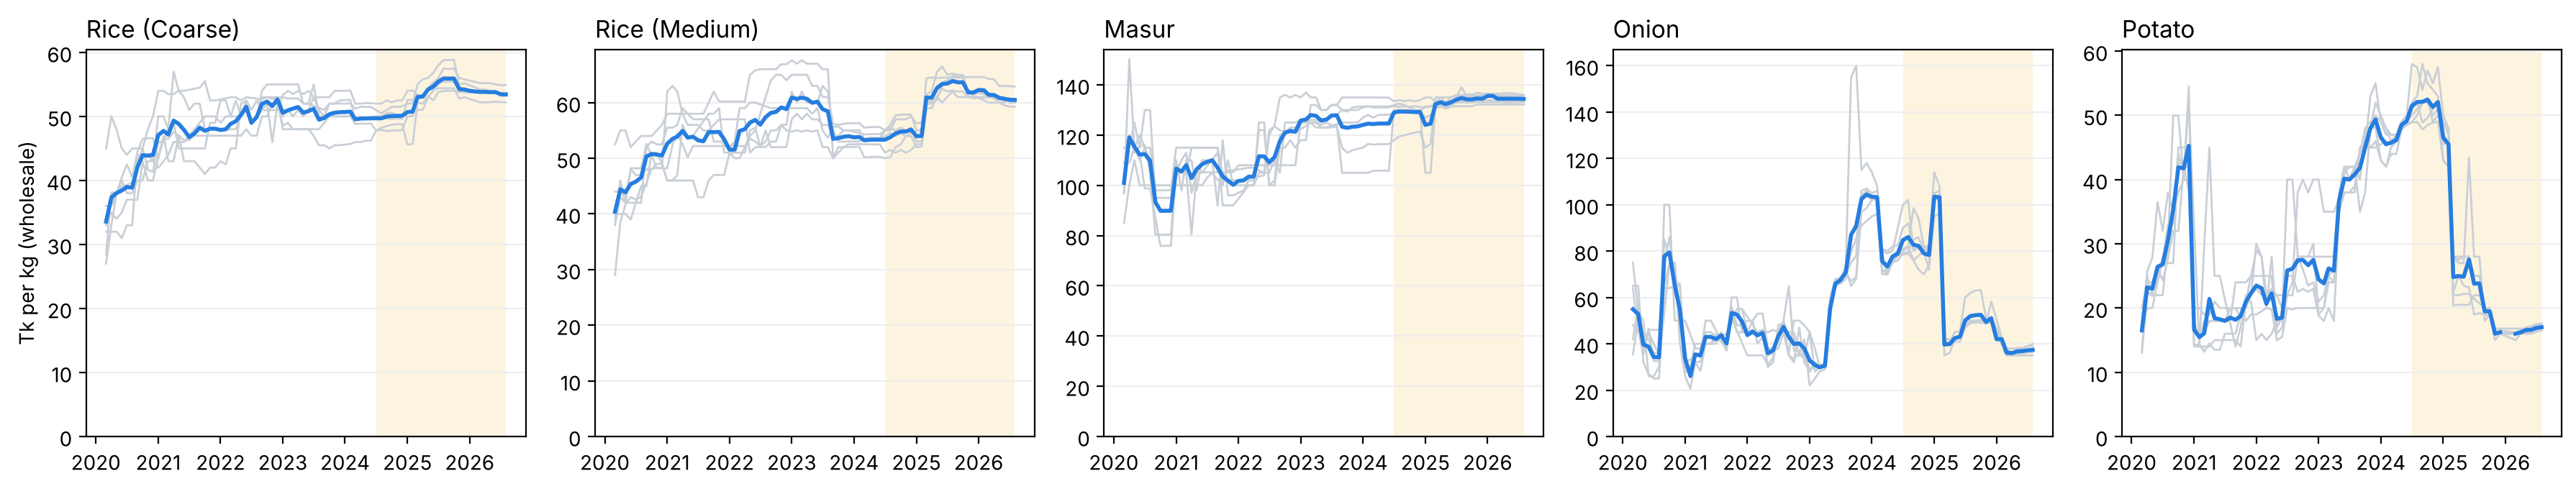

In [3]:
crops = ["Rice (Coarse)", "Rice (Medium)", "Masur", "Onion", "Potato"]
fig, axs = plt.subplots(1, 5, figsize=(18, 3.5), sharex=True)
for ax, c in zip(axs, crops):
    w = raw[raw.commodity == c].pivot(index="month", columns="town", values="price_tk_per_kg")
    for t in w: ax.plot(w.index, w[t].interpolate(limit=2, limit_area="inside"), color="#c9cfd6", lw=1)
    ax.plot(w.index, w.mean(axis=1), color="#257de0", lw=2)
    ax.axvspan(pd.Timestamp("2024-07-01"), w.index.max(), color="#f2a600", alpha=.12, lw=0)
    ax.set_title(c, loc="left"); ax.set_ylim(bottom=0); ax.grid(axis="y", color="#eee")
axs[0].set_ylabel("Tk per kg (wholesale)")
plt.tight_layout(); plt.show()

## 4. Features (only information available at the time)

Target: next month's price change (%). Features: changes over 1, 2, 3 and 12 months, last year's change for the same
month, distance from the 6-month average, season (month as sine/cosine) and crop. One model is trained on all 30 series together.
Gaps of up to 2 months are filled by interpolation; longer gaps are left out.

In [4]:
crop_code = {c: i for i, c in enumerate(crops)}
rows = []
for (c, t), g in raw.groupby(["commodity", "town"]):
    s = g.set_index("month")["price_tk_per_kg"].sort_index().asfreq("MS").interpolate(limit=2, limit_area="inside")
    f = pd.DataFrame({"price": s})
    f["next_price"] = s.shift(-1)
    f["target"] = s.shift(-1) / s - 1
    for k in (1, 2, 3, 12):
        f[f"ret_{k}"] = s / s.shift(k) - 1
    f["seas_change"] = s.shift(11) / s.shift(12) - 1
    f["dev_ma6"] = s / s.rolling(6).mean() - 1
    f["month_sin"], f["month_cos"] = np.sin(2*np.pi*f.index.month/12), np.cos(2*np.pi*f.index.month/12)
    f["crop_code"], f["commodity"], f["town"] = crop_code[c], c, t
    rows.append(f.reset_index())
FEATURES = ["ret_1", "ret_2", "ret_3", "ret_12", "seas_change", "dev_ma6", "month_sin", "month_cos", "crop_code"]
data = pd.concat(rows).dropna(subset=FEATURES + ["target"]).reset_index(drop=True)
data["series"] = data.commodity + " | " + data.town
print("usable rows:", len(data), "| first usable month:", data.month.min().date())

usable rows: 1938 | first usable month: 2021-03-01


## 5. Rolling-origin forecasts

For every test month *T*: train on all rows with month < *T* (their next-month price is already known at *T*), then
forecast *T* for every series. Same no-leakage rule as the FIFA project, adapted to time.

In [5]:
MODELS = ["Naive", "Seasonal change", "Random Forest", "Gradient Boosting"]
preds = []
for T in sorted(data.month.unique()):
    if T < pd.Timestamp(min(a for a, b in WINDOWS.values())):
        continue
    train, now = data[data.month < T], data[data.month == T].copy()
    rf = RandomForestRegressor(n_estimators=300, max_depth=5, min_samples_leaf=10, random_state=SEED, n_jobs=-1)
    gb = GradientBoostingRegressor(n_estimators=150, max_depth=2, learning_rate=0.05, subsample=0.8, random_state=SEED)
    rf.fit(train[FEATURES], train.target); gb.fit(train[FEATURES], train.target)
    now["Naive"], now["Seasonal change"] = 0.0, now.seas_change
    now["Random Forest"], now["Gradient Boosting"] = rf.predict(now[FEATURES]), gb.predict(now[FEATURES])
    preds.append(now)
pred = pd.concat(preds, ignore_index=True)
pred["window"] = None
for name, (a, b) in WINDOWS.items():
    pred.loc[pred.month.between(a, b), "window"] = name
pred = pred.dropna(subset=["window"])
print(pred.groupby("window").agg(forecasts=("target", "size"), months=("month", "nunique")))

                                forecasts  months
window                                           
Crisis (Jul 2024–Jul 2026)            744      25
Pre-crisis (Jul 2023–Jun 2024)        360      12


## 6. Accuracy
MAE in Tk per kg. Direction = share of months (where the price moved) in which the model got up/down right.

In [6]:
def accuracy(g, m):
    fc = g.price * (1 + g[m]); moved = g.target != 0
    return pd.Series({"MAE (Tk/kg)": (g.next_price - fc).abs().mean(),
                      "MAPE (%)": ((g.next_price - fc).abs() / g.next_price).mean() * 100,
                      "Direction correct (%)": (np.sign(g.loc[moved, m]) == np.sign(g.loc[moved, "target"])).mean() * 100})
acc = pd.concat({w: pd.DataFrame({m: accuracy(g, m) for m in MODELS}).T for w, g in pred.groupby("window")}).round(2)
acc

MAE (Tk/kg)  MAPE (%)  Direction correct (%)
Crisis (Jul 2024–Jul 2026)     Naive                     2.05      4.54                   0.00
                               Seasonal change           3.32      6.88                  47.79
                               Random Forest             2.58      6.06                  53.51
                               Gradient Boosting         2.66      6.24                  57.38
Pre-crisis (Jul 2023–Jun 2024) Naive                     2.56      3.38                   0.00
                               Seasonal change           6.24      8.34                  39.93
                               Random Forest             2.80      3.71                  56.41
                               Gradient Boosting         2.93      3.89                  54.95

## 7. Decision value: sell now or store one month?

Rule: wait only if forecast price × (1 − storage cost) > today's price.
**Gain** = extra revenue vs always selling now (%). **Share of perfect** = how much of a perfect forecaster's gain the model
captures (median across series; negative = worse than not forecasting).

In [7]:
def revenue(g, m, c):
    wait_value = g.next_price * (1 - c)
    if m == "Perfect foresight": return np.maximum(g.price, wait_value)
    if m == "Always wait": return wait_value
    return np.where((1 + g[m]) * (1 - c) > 1, wait_value, g.price)

ALL = MODELS + ["Always wait", "Perfect foresight"]
rec = []
for w, gw in pred.groupby("window"):
    for c in STORAGE_COSTS:
        for s, g in gw.groupby("series"):
            base, perf = g.price.mean(), np.mean(revenue(g, "Perfect foresight", c))
            for m in ALL:
                r = np.mean(revenue(g, m, c))
                rec.append({"window": w, "storage": c, "series": s, "commodity": g.commodity.iloc[0], "model": m,
                            "gain_pct": (r / base - 1) * 100,
                            "share_of_perfect": (r - base) / (perf - base) * 100 if perf > base + 1e-9 else np.nan})
dv = pd.DataFrame(rec)
summary = (dv.groupby(["window", "storage", "model"])
             .agg(gain_pct=("gain_pct", "mean"), share_of_perfect=("share_of_perfect", "median"),
                  series_with_gain=("gain_pct", lambda x: f"{(x > 1e-9).sum()}/{len(x)}")).round(2))
summary

gain_pct  share_of_perfect series_with_gain
window                         storage model                                                         
Crisis (Jul 2024–Jul 2026)     0.01    Always wait           -2.40           -175.66             0/30
                                       Gradient Boosting     -0.70             -8.09             7/30
                                       Naive                  0.00              0.00             0/30
                                       Perfect foresight      1.03            100.00            29/30
                                       Random Forest         -1.27              0.00             1/30
                                       Seasonal change       -0.46            -46.22             3/30
                               0.02    Always wait           -3.39           -356.02             0/30
                                       Gradient Boosting     -0.36              0.00             5/30
                                       Naive                  0.00              0.00             0/30
                                       Perfect foresight      0.85            100.00            26/30
                                       Random Forest         -1.29              0.00             1/30
                                       Seasonal change       -0.64            -65.14             2/30
                               0.05    Always wait           -6.34          -1344.70             0/30
                                       Gradient Boosting     -0.64              0.00             1/30
                                       Naive                  0.00              0.00             0/30
                                       Perfect foresight      0.59            100.00            22/30
                                       Random Forest         -0.72              0.00             1/30
                                       Seasonal change       -0.72           -104.35             0/30
Pre-crisis (Jul 2023–Jun 2024) 0.01    Always wait           -0.45           -403.17            12/30
                                       Gradient Boosting      0.41              0.00            11/30
                                       Naive                  0.00              0.00             0/30
                                       Perfect foresight      1.62            100.00            27/30
                                       Random Forest          0.07              0.00            11/30
                                       Seasonal change       -0.24            -25.07             9/30
                               0.02    Always wait           -1.46            -38.49             5/30
                                       Gradient Boosting      0.24              0.00             7/30
                                       Naive                  0.00              0.00             0/30
                                       Perfect foresight      1.35            100.00            20/30
                                       Random Forest         -0.14              0.00             6/30
                                       Seasonal change       -0.35            -35.78             6/30
                               0.05    Always wait           -4.47           -253.61             0/30
                                       Gradient Boosting      0.05              0.00             5/30
                                       Naive                  0.00              0.00             0/30
                                       Perfect foresight      0.92            100.00            13/30
                                       Random Forest         -0.17             -3.57             0/30
                                       Seasonal change       -0.60            -21.67             2/30

## 8. Chart: gain vs selling now, by window (2% storage cost)

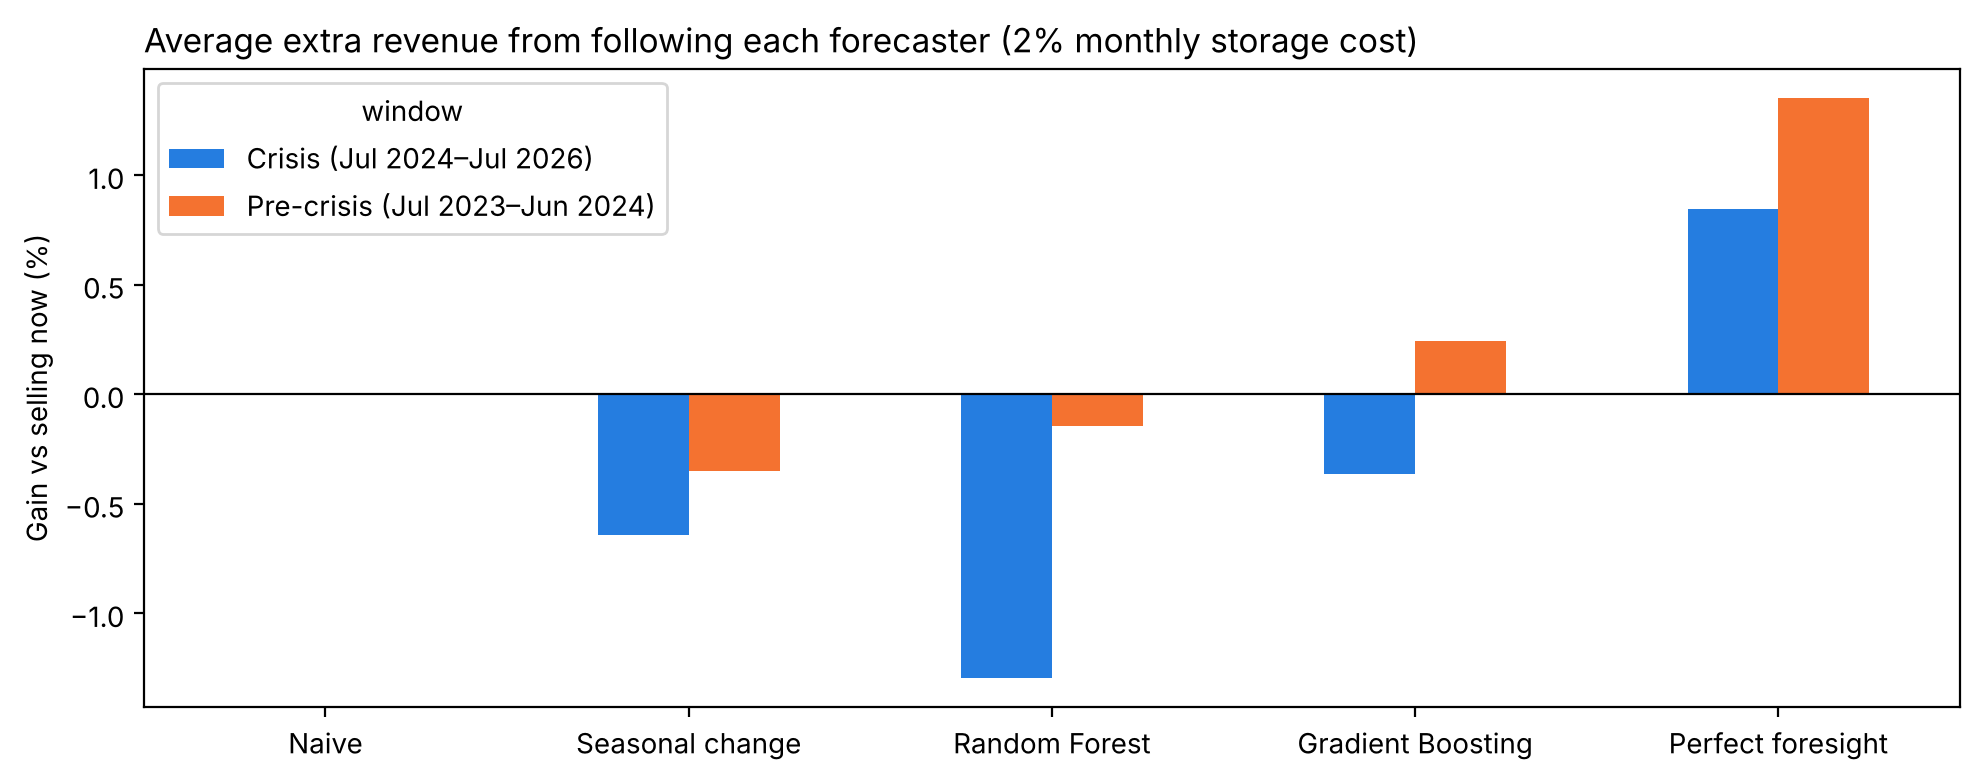

In [8]:
sub = dv[(dv.storage == 0.02) & dv.model.isin(MODELS + ["Perfect foresight"])]
pv = sub.groupby(["window", "model"]).gain_pct.mean().unstack()[MODELS + ["Perfect foresight"]]
ax = pv.T.plot(kind="bar", figsize=(10, 4), rot=0, color=["#257de0", "#f47230"])
ax.axhline(0, color="black", lw=.8); ax.set_ylabel("Gain vs selling now (%)"); ax.set_xlabel("")
ax.set_title("Average extra revenue from following each forecaster (2% monthly storage cost)", loc="left")
plt.tight_layout(); plt.show()

## 9. By crop (crisis window, 2% storage cost)

In [9]:
crisis = [w for w in WINDOWS if w.startswith("Crisis")][0]
by_crop = (dv[(dv.window == crisis) & (dv.storage == 0.02)]
           .pivot_table(index="commodity", columns="model", values="gain_pct", aggfunc="mean")[ALL].round(2))
by_crop

model,Naive,Seasonal change,Random Forest,Gradient Boosting,Always wait,Perfect foresight
commodity,,,,,,
Masur,0.0,-0.08,0.08,0.09,-1.84,0.21
Onion,0.0,-0.66,-4.10,0.30,-5.23,2.66
Potato,0.0,-1.96,-2.43,-2.15,-6.62,0.65
Rice (Coarse),0.0,-0.23,0.00,0.00,-1.72,0.22
Rice (Medium),0.0,-0.28,-0.02,-0.06,-1.52,0.49


## 10. Is the ML gain real or luck?

Wilcoxon signed-rank test across the 30 series: does Gradient Boosting's gain differ from zero (selling now)
and from the Naive/Seasonal rule? p < 0.05 = unlikely to be chance. With 30 series this test is rough; report it with that caveat.

In [10]:
out = []
for w in WINDOWS:
    for c in STORAGE_COSTS:
        g = dv[(dv.window == w) & (dv.storage == c)].pivot(index="series", columns="model", values="gain_pct")
        for other in ["Seasonal change"]:
            for m in ["Gradient Boosting", "Random Forest"]:
                d0 = g[m]; d1 = g[m] - g[other]
                out.append({"window": w, "storage": c, "model": m,
                            "mean gain %": d0.mean(), "p vs sell-now": wilcoxon(d0).pvalue if (d0 != 0).any() else np.nan,
                            f"mean diff vs {other}": d1.mean(),
                            f"p vs {other}": wilcoxon(d1).pvalue if (d1 != 0).any() else np.nan})
pd.DataFrame(out).round(3)

,window,storage,model,mean gain %,p vs sell-now,mean diff vs Seasonal change,p vs Seasonal change
0,Pre-crisis (Jul 2023–Jun 2024),0.01,Gradient Boosting,0.413,0.355,0.652,0.006
1,Pre-crisis (Jul 2023–Jun 2024),0.01,Random Forest,0.065,0.737,0.305,0.071
2,Pre-crisis (Jul 2023–Jun 2024),0.02,Gradient Boosting,0.243,0.970,0.594,0.012
3,Pre-crisis (Jul 2023–Jun 2024),0.02,Random Forest,-0.143,0.334,0.207,0.112
4,Pre-crisis (Jul 2023–Jun 2024),0.05,Gradient Boosting,0.053,0.917,0.649,0.001
5,Pre-crisis (Jul 2023–Jun 2024),0.05,Random Forest,-0.171,0.018,0.425,0.004
6,Crisis (Jul 2024–Jul 2026),0.01,Gradient Boosting,-0.701,0.035,-0.238,0.328
7,Crisis (Jul 2024–Jul 2026),0.01,Random Forest,-1.270,0.002,-0.807,0.715
8,Crisis (Jul 2024–Jul 2026),0.02,Gradient Boosting,-0.364,0.113,0.277,0.036
9,Crisis (Jul 2024–Jul 2026),0.02,Random Forest,-1.294,0.002,-0.654,0.495


## 11. Save results for the paper

In [11]:
acc.to_csv("results_accuracy.csv"); summary.to_csv("results_decision_value.csv")
dv.to_csv("results_decision_value_by_series.csv", index=False); by_crop.to_csv("results_by_crop_crisis.csv")
print("Saved 4 CSV files (Colab: folder icon on the left).")

Saved 4 CSV files (Colab: folder icon on the left).


## How to read the results (for the Results section)

1. **Accuracy:** do the ML models beat Naive on MAE and direction, in each window?
2. **Money:** at 2% storage, does any forecaster produce a positive gain vs selling now?
3. **Accuracy ≠ money?** Is the most accurate model also the most profitable?
4. **Crisis effect:** does decision value shrink, grow, or flip sign after July 2024?
5. **Crops:** which crops reward waiting (storable, seasonal) and which punish it (potato/onion crashes)?
6. **Robustness:** do conclusions hold at 1% and 5% storage cost?

Limitations: wholesale (not farm-gate) prices; monthly (farmers decide weekly); 30 series; 108 copied and
10 typo values removed from the bulletins; storage cost is assumed, not measured.